## Imports and loads

In [1]:
import pandas as pd
import numpy as np
from sklearn import metrics as mt
from sklearn.model_selection import train_test_split
import random



## 1 - Classificação

Métricas de performance: Accuracy, Precision, Recall e F1-Score

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

x_all = np.array(pd.read_csv('X_training.csv'))
y_all = np.array(pd.read_csv('y_training.csv')).ravel()

X_train, x_test, Y_train, y_test  = train_test_split(x_all, y_all, test_size=0.3, random_state=random.randint(1, 100))
x_train, x_val, y_train, y_val = train_test_split(X_train, Y_train, test_size=0.3)

In [5]:
def get_metrics_classification(classifier, x_train, x_val, x_test, y_train, y_val, y_test):
    y_pred_train = classifier.predict(x_train)
    y_pred_val = classifier.predict(x_val)
    y_pred_test = classifier.predict(x_test)


    acc_train = mt.accuracy_score(y_train, y_pred_train)
    p_train = mt.precision_score(y_train, y_pred_train)
    r_train = mt.recall_score(y_train, y_pred_train)
    f1_train = mt.f1_score(y_train, y_pred_train)


    acc_val = mt.accuracy_score(y_val, y_pred_val)
    p_val = mt.precision_score(y_val, y_pred_val)
    r_val = mt.recall_score(y_val, y_pred_val)
    f1_val = mt.f1_score(y_val, y_pred_val)


    acc_test = mt.accuracy_score(y_test, y_pred_test)
    p_test = mt.precision_score(y_test, y_pred_test)
    r_test = mt.recall_score(y_test, y_pred_test)
    f1_test = mt.f1_score(y_test, y_pred_test)

    print('Treino:', acc_train, p_train, r_train, f1_train)
    print('Valid:', acc_val, p_val, r_val, f1_val)
    print('Teste:', acc_test, p_test, r_test, f1_test)


### 1 - KNN 
Parâmetros: n_neighbors

In [4]:
acc_max = 0
for n_neighbors in range(2, 10):
    
    knn_sample = KNeighborsClassifier(n_neighbors= n_neighbors)
    knn_sample.fit(x_train, y_train)
    y_pred = knn_sample.predict(x_val)
    acc_pred = mt.accuracy_score(y_pred=y_pred, y_true=y_val)
    print('n_neighbors = ', n_neighbors, acc_pred)
    if(acc_pred>acc_max):
        knn_classifier = knn_sample
        acc_max = acc_pred
        


n_neighbors =  2 0.6310743367480957
n_neighbors =  3 0.6442737063304439
n_neighbors =  4 0.6373785132650381
n_neighbors =  5 0.6438140267927502
n_neighbors =  6 0.6413186235881271
n_neighbors =  7 0.64026792750197
n_neighbors =  8 0.6382322038350408
n_neighbors =  9 0.6359338061465721


In [6]:
get_metrics_classification(knn_classifier, x_train, x_val, x_test, y_train, y_val, y_test)

Treino: 0.8172070246538332 0.7992511912865895 0.7680382023941912 0.7833338893151417
Valid: 0.6442737063304439 0.5968329374505147 0.5676204819277109 0.581860285604014
Teste: 0.6460124109400138 0.5981247274313127 0.5774129039048521 0.5875863546296791


### 2 - Decision Tree 
Parametros: max_depth

In [14]:
acc_max = 0
dt_classifier = []
hiperparameter_list = [None] + [2, 4, 6, 8, 10, 15, 20, 30, 40, 50]
for hp in hiperparameter_list:
    
    classifier_sample = DecisionTreeClassifier(max_depth=hp)
    classifier_sample.fit(x_train, y_train)
    y_pred = classifier_sample.predict(x_val)
    acc_pred = mt.accuracy_score(y_val, y_pred)
    print('max_depth= ', hp, acc_pred)
    if(acc_pred>acc_max):
        dt_classifier = classifier_sample
        acc_max = acc_pred
        

max_depth=  None 0.9371552403467297
max_depth=  2 0.8574336748095613
max_depth=  4 0.8930260047281324
max_depth=  6 0.9245468873128447
max_depth=  8 0.9364985552928815
max_depth=  10 0.9411610191752036
max_depth=  15 0.9426713947990544
max_depth=  20 0.9399133175728921
max_depth=  30 0.9371552403467297
max_depth=  40 0.9387969529813501
max_depth=  50 0.9374835828736537


In [15]:
get_metrics_classification(dt_classifier, x_train, x_val, x_test, y_train, y_val, y_test)

Treino: 0.9863784757401779 0.9885801042973134 0.9796559167920456 0.984097778945985
Valid: 0.9426713947990544 0.934982651983708 0.933433734939759 0.9342075514356771
Teste: 0.9440128706044587 0.9335287344289752 0.9386380381012525 0.9360764144011755


### 3 - Random Forest
Parâmetros: n_estimators, max_depth

In [ ]:
acc_max = 0
rf_classifier = []
hiperparameter_list_1 = [None] + [2, 4, 6, 8, 10, 15, 20, 30, 40, 50, 70, 100]
hiperparameter_list_2 = [10, 15, 20, 30, 40, 50, 100, 200, 500, 750, 1000, 2000]

for hp1 in hiperparameter_list_1:
    for hp2 in hiperparameter_list_2:
        
        classifier_sample = RandomForestClassifier(max_depth=hp1, n_estimators=hp2)
        classifier_sample.fit(x_train, y_train)
        y_pred = classifier_sample.predict(x_val)
        acc_pred = mt.accuracy_score(y_val, y_pred)
        
        if(acc_pred>acc_max):
            print('parameters= ', hp1, hp2, acc_pred)
            rf_classifier = classifier_sample
            acc_max = acc_pred




parameters=  None 10 0.9550827423167849
parameters=  None 15 0.9578408195429472
parameters=  None 20 0.9579721565537168
parameters=  None 30 0.9609272392960336
parameters=  None 50 0.9610585763068032
parameters=  None 100 0.9612555818229577
parameters=  None 200 0.9625689519306541
parameters=  None 1000 0.9632256369845023
parameters=  30 500 0.9633569739952719
parameters=  30 1000 0.9634226425006567
parameters=  40 500 0.9636853165221959
Treino: 1.0 1.0 1.0 1.0
Valid: 0.9636853165221959 0.9732545482817603 0.9426204819277109 0.9576926019432331
Teste: 0.960974488623305 0.9680805020558321 0.9416903483843806 0.9547030891532838


In [17]:
get_metrics_classification(rf_classifier, x_train, x_val, x_test, y_train, y_val, y_test)

Treino: 1.0 1.0 1.0 1.0
Valid: 0.9636853165221959 0.9732545482817603 0.9426204819277109 0.9576926019432331
Teste: 0.960974488623305 0.9680805020558321 0.9416903483843806 0.9547030891532838


In [18]:
rf_classifier

RandomForestClassifier(max_depth=40, n_estimators=500)

### 4 - Logistic Regression
Parâmetros: C, solver, max_iter

In [ ]:
acc_max = 0
lr_classifier = []
C_list = [0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1, 10, 100]
solver_list = ['lbfgs', 'liblinear', 'saga']
max_iter_list= [10, 25, 50, 100, 200, 500]

for hp1 in C_list:
    for hp2 in solver_list:
        for hp3 in max_iter_list:
                
            
            classifier_sample = LogisticRegression(C = hp1, solver=hp2,max_iter=hp3)
            classifier_sample.fit(x_train, y_train)
            y_pred = classifier_sample.predict(x_val)
            acc_pred = mt.accuracy_score(y_val, y_pred)
            
            if(acc_pred>acc_max):
                print('parameters= ', hp1, hp2, hp3, acc_pred)
                lr_classifier = classifier_sample
                acc_max = acc_pred




In [24]:
get_metrics_classification(lr_classifier, x_train, x_val, x_test, y_train, y_val, y_test)

Treino: 0.6658786446020488 0.6364580835930632 0.520965526264146 0.5729496402877698
Valid: 0.668702390333596 0.646788146512056 0.5292168674698795 0.582125403793589
Teste: 0.6662376465180418 0.6464435146443515 0.5203662772339753 0.5765933873695259


## 2 - Regressão

Métricas de performance: R2, MSE, RMSE, MAE e MAPE

In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Lasso
from sklearn.linear_model import Ridge
from sklearn.linear_model import ElasticNet


In [3]:
x_train = np.array(pd.read_csv('data/regression/X_training_regression.csv'))
x_val = np.array(pd.read_csv('data/regression/X_validation_regression.csv'))
x_test = np.array(pd.read_csv('data/regression/X_test_regression.csv'))

y_train = np.array(pd.read_csv('data/regression/y_training_regression.csv')).ravel()
y_val = np.array(pd.read_csv('data/regression/y_val_regression.csv')).ravel()
y_test = np.array(pd.read_csv('data/regression/y_test_regression.csv')).ravel()

In [4]:
def get_metrics_regression(classifier, x_train, x_val, x_test, y_train, y_val, y_test):
    y_pred_train = classifier.predict(x_train)
    y_pred_val = classifier.predict(x_val)
    y_pred_test = classifier.predict(x_test)

    r2_train = mt.r2_score(y_train, y_pred_train)
    mse_train = mt.mean_squared_error(y_train, y_pred_train)
    rmse_train = np.sqrt(mse_train)
    mae_train = mt.mean_absolute_error(y_train, y_pred_train)
    mape_train = mt.mean_absolute_percentage_error(y_train, y_pred_train)

    r2_val = mt.r2_score(y_val, y_pred_val)
    mse_val = mt.mean_squared_error(y_val, y_pred_val)
    rmse_val = np.sqrt(mse_val)
    mae_val = mt.mean_absolute_error(y_val, y_pred_val)
    mape_val = mt.mean_absolute_percentage_error(y_val, y_pred_val)

    r2_test = mt.r2_score(y_test, y_pred_test)
    mse_test = mt.mean_squared_error(y_test, y_pred_test)
    rmse_test = np.sqrt(mse_test)
    mae_test = mt.mean_absolute_error(y_test, y_pred_test)
    mape_test = mt.mean_absolute_percentage_error(y_test, y_pred_test)

    print('Resultados: R2, MSE, RMSE, MAE, e MAPE')
    print('Treino:', r2_train, mse_train, rmse_train,mae_train, mape_train)
    print('Valid:',r2_val, mse_val, rmse_val,mae_val, mape_val)
    print('Teste:', r2_test, mse_test, rmse_test, mae_test, mape_test)


### 1 - Linear Regression

Parâmetros: 

In [17]:
mape_min = 1000000
regressor = []

                
classifier_sample = LinearRegression()
classifier_sample.fit(x_train, y_train)
y_pred = classifier_sample.predict(x_val)
mape_pred = mt.mean_absolute_percentage_error(y_val, y_pred)
regressor = classifier_sample
print(regressor)

LinearRegression()


In [18]:
get_metrics_regression(regressor, x_train, x_val, x_test, y_train, y_val, y_test)

Resultados: R2, MSE, RMSE, MAE, e MAPE
Treino: 0.04605830473391881 455.9961118256269 21.354065463644783 16.998249066011095 8.653185943804512
Valid: 0.0399248303815406 458.44704184393123 21.41137645841414 17.039753759960327 8.682541883735297
Teste: 0.052317119521687716 461.4277193363895 21.48086868207125 17.12996509166612 8.521859277849837


### 2 - Decision Tree Regressor
Parâmetros: max_depth

In [56]:
mape_min = 1000000
rf_classifier = []
max_depth_list = [2, 3, 4,5, 6, 8, 10, 15, 20, 30, 40, 50, 100, 200]

for max_depth in max_depth_list:   
                
        classifier_sample = DecisionTreeRegressor(max_depth=max_depth)
        classifier_sample.fit(x_train, y_train)
        y_pred = classifier_sample.predict(x_val)
        mape_pred = mt.mean_absolute_percentage_error(y_val, y_pred)
        
        if(mape_pred<mape_min):
            print('parameters= ', max_depth, mape_pred)
            dt_regressor = classifier_sample
            mape_min = mape_pred

parameters=  2 8.480124627460386
parameters=  3 8.469921603015896
parameters=  5 8.395778483246199
parameters=  6 8.324422504826854
parameters=  8 7.951215978381485
parameters=  10 7.878108660969305
parameters=  15 7.545150076543111
parameters=  20 7.007948631149401
parameters=  30 6.966706983279057
parameters=  100 6.854122941448486


In [57]:
get_metrics_regression(dt_regressor, x_train, x_val, x_test, y_train, y_val, y_test)

Resultados: R2, MSE, RMSE, MAE, e MAPE
Treino: 0.9917566957405923 3.940402971731975 1.9850448286454327 0.21409852496986279 0.08262787375974134
Valid: -0.3009260714883373 621.2073054326472 24.924030681907116 17.15833928439768 6.854122941448486
Teste: -0.21270965219874105 590.4695131232743 24.29957845567026 16.65408307735093 6.183992047994211


### 3 - Random Forest Regressor
Parâmetros: n_estimators e max_depth

In [58]:
mape_min = 1000000
rf_regressor = []
max_depth_list = [2, 3, 4,5, 6, 8, 10, 15, 20, 30, 40, 50, 100, 200]
n_estimator_list = [10, 25, 50, 100, 200, 500, 1000]

for max_depth in max_depth_list:   
        for n_estimator in n_estimator_list:
                
            classifier_sample = RandomForestRegressor(n_estimators = n_estimator, max_depth=max_depth)
            classifier_sample.fit(x_train, y_train)
            y_pred = classifier_sample.predict(x_val)
            mape_pred = mt.mean_absolute_percentage_error(y_val, y_pred)
            
            if(mape_pred<mape_min):
                print('parameters= ', max_depth, n_estimator, mape_pred)
                rf_regressor = classifier_sample
                mape_min = mape_pred

print('-------------------------')
print(rf_regressor)

parameters=  2 8.49089882172482
parameters=  2 8.47303433675928
parameters=  3 8.46818116006455
parameters=  4 8.434860163011304
parameters=  5 8.387366519281288
parameters=  5 8.385460505890018
parameters=  5 8.38487831012489
parameters=  6 8.255602770932573
parameters=  8 7.980658902798251
parameters=  10 7.938692279431746
parameters=  10 7.816829529203491
parameters=  15 7.22667754693784
parameters=  20 6.995367823941694
parameters=  40 6.9834288285867885
parameters=  50 6.899347439080162
-------------------------
RandomForestRegressor(max_depth=50, n_estimators=10)


In [59]:
get_metrics_regression(rf_regressor, x_train, x_val, x_test, y_train, y_val, y_test)

Resultados: R2, MSE, RMSE, MAE, e MAPE
Treino: 0.8650884282912455 64.4894257634025 8.030530851905278 5.433860333447301 2.5561881043202974
Valid: 0.27575386668309254 345.83593857342663 18.596664716379294 13.62726925294593 6.899347439080162
Teste: 0.2886066337385216 346.378124272324 18.611236505732872 13.741667922541428 6.55691344914022


### 4 - Polinomial Regression
Parâmetros: degree

In [8]:
mape_min = 1000000
poly_regressor = []
degree_list = [1, 2, 3]


for degree in degree_list:  
            print(degree) 
                
            classifier_sample = make_pipeline(PolynomialFeatures(degree=degree), LinearRegression())
            classifier_sample.fit(x_train, y_train)
            y_pred = classifier_sample.predict(x_val)
            mape_pred = mt.mean_absolute_percentage_error(y_val, y_pred)
            
            if(mape_pred<mape_min):
                print('parameters= ', degree, mape_pred)
                poly_regressor = classifier_sample
                mape_min = mape_pred

print('-------------------------')
print(poly_regressor)

1
parameters=  1 8.682541883735157
2
parameters=  2 8.547931034605389
3
-------------------------
Pipeline(steps=[('polynomialfeatures', PolynomialFeatures()),
                ('linearregression', LinearRegression())])


In [9]:
get_metrics_regression(poly_regressor, x_train, x_val, x_test, y_train, y_val, y_test)

Resultados: R2, MSE, RMSE, MAE, e MAPE
Treino: 0.09419491057528084 432.9862096386579 20.80832068280999 16.458031755824436 8.350539820928125
Valid: 0.06647668389711636 445.7682234712755 21.11322390046758 16.749939090484027 8.547931034605389
Teste: 0.09007934329900802 443.0412557275451 21.048545216416862 16.720535025987555 8.242463577057906


### 5 - Linear Regression Lasso 
Parâmetros: alpha e max_iter

In [18]:
alpha_list = [0.01, 0.1, 1, 10,20,  50, 100, 200]
max_iter_list = [10, 50, 100, 500, 1000, 5000, 10000]

mape_min = 1000000
lr_lasso = []



for alpha in alpha_list:  
        print(alpha)
        for max_iter in max_iter_list: 
                
            classifier_sample = Lasso(alpha=alpha, max_iter=max_iter)
            classifier_sample.fit(x_train, y_train)
            y_pred = classifier_sample.predict(x_val)
            mape_pred = mt.mean_absolute_percentage_error(y_val, y_pred)
            
            if(mape_pred<mape_min):
                print('parameters= ', alpha, max_iter)
                lr_lasso = classifier_sample
                mape_min = mape_pred

print('-------------------------')
print(lr_lasso)

0.01
parameters=  0.01 10
0.1
1
10
parameters=  10 10
20


/home/matheus2neuron/.pyenv/versions/2neuron_python10/lib/python3.10/site-packages/sklearn/linear_model/_coordinate_descent.py:628: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.603e+05, tolerance: 5.042e+02
  model = cd_fast.enet_coordinate_descent(
/home/matheus2neuron/.pyenv/versions/2neuron_python10/lib/python3.10/site-packages/sklearn/linear_model/_coordinate_descent.py:628: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.446e+03, tolerance: 5.042e+02
  model = cd_fast.enet_coordinate_descent(


50
100
200
-------------------------
Lasso(alpha=10, max_iter=10)


In [19]:
get_metrics_regression(lr_lasso, x_train, x_val, x_test, y_train, y_val, y_test)

Resultados: R2, MSE, RMSE, MAE, e MAPE
Treino: 0.0 478.012559979818 21.863498347241183 17.3650904457618 8.742212844953096
Valid: -7.197077047660372e-07 477.5119556252973 21.85204694359998 17.352835945449478 8.678722362628074
Teste: -0.0001242400734962068 486.96146850013093 22.06720345898254 17.551491953962177 8.714549642759494


### 6 - Linear Regression Ridge
Parâmetros: alpha e max_iter

In [28]:
alpha_list = [0.001, 0.01, 0.1, 1, 10,20,  50, 100, 200, 300, 350, 400, 500, 1000]
max_iter_list = [1, 2,3, 4, 5, 10, 50, 100, 500, 1000, 5000]

mape_min = 1000000
lr_ridge = []



for alpha in alpha_list:  
        print(alpha)
        for max_iter in max_iter_list: 
                
            classifier_sample = Ridge(alpha=alpha, max_iter=max_iter)
            classifier_sample.fit(x_train, y_train)
            y_pred = classifier_sample.predict(x_val)
            mape_pred = mt.mean_absolute_percentage_error(y_val, y_pred)
            
            if(mape_pred<mape_min):
                print('parameters= ', alpha, max_iter)
                lr_ridge = classifier_sample
                mape_min = mape_pred

print('-------------------------')
print(lr_ridge)

0.001
parameters=  0.001 1
0.01
parameters=  0.01 1
0.1
parameters=  0.1 1
1
parameters=  1 1
10
parameters=  10 1
20
parameters=  20 1
50
parameters=  50 1
100
parameters=  100 1
200
parameters=  200 1
300
parameters=  300 1
350
400
500
1000
-------------------------
Ridge(alpha=300, max_iter=1)


In [29]:
get_metrics_regression(lr_ridge, x_train, x_val, x_test, y_train, y_val, y_test)

Resultados: R2, MSE, RMSE, MAE, e MAPE
Treino: 0.03829360017401906 459.70773812979155 21.440796116977364 17.06196907060251 8.672325796098129
Valid: 0.03472227532264982 460.9313222963946 21.46931117424112 17.05520086443711 8.671947447322681
Teste: 0.04143241504718409 466.727492567268 21.603876794854852 17.192953204074893 8.628200152884355


### 7 - Linear Regression Elastic Net
Parâmetros: alpha, l1_ratio e max_iter

In [ ]:
alpha_list = [1e-6, 5e-6, 0.00001, 5e-5, 0.0001, 5e-4, 0.001, 5e-3,  0.01, 0.05, 0.1, 0.5, 1, 5, 10,20]
max_iter_list = [1, 2,3, 4, 5, 10, 50, 100, 500]
l1_ratio_list =  [0.1, 0.3, 0.5, 0.7, 0.9, 1]

mape_min = 1000000
lr_ridge = []



for alpha in alpha_list:  
        print(alpha)
        for max_iter in max_iter_list: 
            for l1_ratio in l1_ratio_list:
                                        
                classifier_sample = ElasticNet(l1_ratio=l1_ratio, alpha=alpha, max_iter=max_iter)
                classifier_sample.fit(x_train, y_train)
                y_pred = classifier_sample.predict(x_val)
                mape_pred = mt.mean_absolute_percentage_error(y_val, y_pred)
                
                if(mape_pred<mape_min):
                    print('parameters= ', alpha, max_iter)
                    lr_elastic = classifier_sample
                    mape_min = mape_pred

print('-------------------------')
print(lr_elastic)

In [36]:
get_metrics_regression(lr_elastic, x_train, x_val, x_test, y_train, y_val, y_test)

Resultados: R2, MSE, RMSE, MAE, e MAPE
Treino: 0.04355238291758745 457.1939739281607 21.3820947039377 17.026436693633794 8.664778804240783
Valid: 0.03542753967532408 460.59455037849375 21.461466640900703 17.078233405772362 8.660427953973626
Teste: 0.0499584395978101 462.57616289313074 21.507583846009545 17.147462847570495 8.511736431110663


### 8 - Polinomial Regression Lasso
Parâmetros: degree, alpha e max_iter

In [ ]:
alpha_list = [1e-10, 5e-10, 1e-9, 5e-9, 1e-8, 5e-8, 1e-7, 5e-7, 1e-6, 5e-6, 0.00001]#, 5e-5, 0.0001, 5e-4, 0.001, 5e-3,  0.01, 0.05, 0.1, 0.5, 1, 5, 10,20]
max_iter_list = [1, 2,3, 4, 5, 10, 50, 100]
degree_list =  [1, 2, 3]

mape_min = 1000000
regressor = []



for alpha in alpha_list:  
        print(alpha)
        for max_iter in max_iter_list: 
            for degree in degree_list:
                classifier_sample = make_pipeline(PolynomialFeatures(degree), Lasso(alpha=alpha, max_iter=max_iter)
)
                classifier_sample.fit(x_train, y_train)
                y_pred = classifier_sample.predict(x_val)
                mape_pred = mt.mean_absolute_percentage_error(y_val, y_pred)
                
                if(mape_pred<mape_min):
                    print('parameters= ', alpha, max_iter, degree)
                    regressor = classifier_sample
                    mape_min = mape_pred

print('-------------------------')
print(regressor)

In [9]:
get_metrics_regression(regressor, x_train, x_val, x_test, y_train, y_val, y_test)

Resultados: R2, MSE, RMSE, MAE, e MAPE
Treino: 0.11607085643975668 422.52923275399996 20.555515871755688 16.248790427066794 8.127155675616237
Valid: -0.07768702801896432 514.6080699339573 22.684974541179393 16.811987693545973 8.51941339642584
Teste: 0.08176120996672398 447.09136296459326 21.144535061443023 16.721308493505433 8.21791781758674


### 9 - Polinomial Regression Ridge
Parâmetros: degree, alpha e max_iter

In [ ]:
alpha_list = [1e-11, 1e-10, 5e-10, 1e-9, 5e-9, 1e-8, 5e-8, 1e-7, 5e-7, 1e-6, 5e-6, 0.00001]#, 5e-5, 0.0001, 5e-4, 0.001, 5e-3,  0.01, 0.05, 0.1, 0.5, 1, 5, 10,20]
max_iter_list = [1, 2,3, 4, 5, 10, 50, 100]
degree_list =  [1, 2, 3]

mape_min = 1000000
regressor = []



for alpha in alpha_list:  
        print(alpha)
        for max_iter in max_iter_list: 
            for degree in degree_list:
                classifier_sample = make_pipeline(PolynomialFeatures(degree), Ridge(alpha=alpha, max_iter=max_iter)
)
                classifier_sample.fit(x_train, y_train)
                y_pred = classifier_sample.predict(x_val)
                mape_pred = mt.mean_absolute_percentage_error(y_val, y_pred)
                
                if(mape_pred<mape_min):
                    print('parameters= ', alpha, max_iter, degree)
                    regressor = classifier_sample
                    mape_min = mape_pred

print('-------------------------')
print(regressor)

In [12]:
print(regressor)

Pipeline(steps=[('polynomialfeatures', PolynomialFeatures()),
                ('ridge', Ridge(alpha=1e-10, max_iter=1))])


In [13]:
get_metrics_regression(regressor, x_train, x_val, x_test, y_train, y_val, y_test)

Resultados: R2, MSE, RMSE, MAE, e MAPE
Treino: 0.09419491057528084 432.9862096386579 20.80832068280999 16.45803175582404 8.350539820928292
Valid: 0.06647668389845052 445.7682234706384 21.113223900452493 16.749939090469027 8.547931034614074
Teste: 0.09007934329938483 443.0412557273616 21.048545216412503 16.72053502598537 8.242463577070252


### 10 - Polinomial Regression Elastic Net
Parâmetros: degree, alpha, l1_ratio e max_iter

In [14]:
alpha_list = [1e-11, 1e-10, 5e-10, 1e-9, 5e-9, 1e-8, 5e-8, 1e-7, 5e-7, 1e-6, 5e-6, 0.00001]#, 5e-5, 0.0001, 5e-4, 0.001, 5e-3,  0.01, 0.05, 0.1, 0.5, 1, 5, 10,20]
max_iter_list = [1, 2,3, 4, 5, 10, 50, 100]
l1_ratio_list =  [0.1, 0.3, 0.5, 0.7, 0.9, 1]
degree_list = [1, 2, 3]
mape_min = 1000000
regressor = []



for alpha in alpha_list:  
        print(alpha)
        for max_iter in max_iter_list: 
            for l1_ratio in l1_ratio_list:
                for degree in degree_list:
                    classifier_sample = make_pipeline(PolynomialFeatures(degree), ElasticNet(alpha=alpha, max_iter=max_iter, l1_ratio=l1_ratio)
    )
                    classifier_sample.fit(x_train, y_train)
                    y_pred = classifier_sample.predict(x_val)
                    mape_pred = mt.mean_absolute_percentage_error(y_val, y_pred)
                    
                    if(mape_pred<mape_min):
                        print('parameters= ', alpha, max_iter, degree)
                        regressor = classifier_sample
                        mape_min = mape_pred

print('-------------------------')
print(regressor)

1e-11
parameters=  1e-11 1 1
parameters=  1e-11 1 2


/home/matheus2neuron/.pyenv/versions/2neuron_python10/lib/python3.10/site-packages/sklearn/linear_model/_coordinate_descent.py:628: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.411e+06, tolerance: 5.042e+02
  model = cd_fast.enet_coordinate_descent(
/home/matheus2neuron/.pyenv/versions/2neuron_python10/lib/python3.10/site-packages/sklearn/linear_model/_coordinate_descent.py:628: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.336e+06, tolerance: 5.042e+02
  model = cd_fast.enet_coordinate_descent(
/home/matheus2neuron/.pyenv/versions/2neuron_python10/lib/python3.10/site-packages/sklearn/linear_model/_coordinate_descent.py:628: ConvergenceWarning: Objective did not converge. You might want to increase the numbe

parameters=  1e-11 1 3
parameters=  1e-11 1 3


/home/matheus2neuron/.pyenv/versions/2neuron_python10/lib/python3.10/site-packages/sklearn/linear_model/_coordinate_descent.py:628: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.411e+06, tolerance: 5.042e+02
  model = cd_fast.enet_coordinate_descent(
/home/matheus2neuron/.pyenv/versions/2neuron_python10/lib/python3.10/site-packages/sklearn/linear_model/_coordinate_descent.py:628: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.336e+06, tolerance: 5.042e+02
  model = cd_fast.enet_coordinate_descent(
/home/matheus2neuron/.pyenv/versions/2neuron_python10/lib/python3.10/site-packages/sklearn/linear_model/_coordinate_descent.py:628: ConvergenceWarning: Objective did not converge. You might want to increase the numbe

parameters=  1e-11 1 3


/home/matheus2neuron/.pyenv/versions/2neuron_python10/lib/python3.10/site-packages/sklearn/linear_model/_coordinate_descent.py:628: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.291e+06, tolerance: 5.042e+02
  model = cd_fast.enet_coordinate_descent(
/home/matheus2neuron/.pyenv/versions/2neuron_python10/lib/python3.10/site-packages/sklearn/linear_model/_coordinate_descent.py:628: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.411e+06, tolerance: 5.042e+02
  model = cd_fast.enet_coordinate_descent(
/home/matheus2neuron/.pyenv/versions/2neuron_python10/lib/python3.10/site-packages/sklearn/linear_model/_coordinate_descent.py:628: ConvergenceWarning: Objective did not converge. You might want to increase the numbe

... (84 outputs left out)

1e-05


/home/matheus2neuron/.pyenv/versions/2neuron_python10/lib/python3.10/site-packages/sklearn/linear_model/_coordinate_descent.py:628: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.291e+06, tolerance: 5.042e+02
  model = cd_fast.enet_coordinate_descent(
/home/matheus2neuron/.pyenv/versions/2neuron_python10/lib/python3.10/site-packages/sklearn/linear_model/_coordinate_descent.py:628: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.411e+06, tolerance: 5.042e+02
  model = cd_fast.enet_coordinate_descent(
/home/matheus2neuron/.pyenv/versions/2neuron_python10/lib/python3.10/site-packages/sklearn/linear_model/_coordinate_descent.py:628: ConvergenceWarning: Objective did not converge. You might want to increase the numbe

-------------------------
Pipeline(steps=[('polynomialfeatures', PolynomialFeatures(degree=3)),
                ('elasticnet',
                 ElasticNet(alpha=1e-11, l1_ratio=1, max_iter=10))])


/home/matheus2neuron/.pyenv/versions/2neuron_python10/lib/python3.10/site-packages/sklearn/linear_model/_coordinate_descent.py:628: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.187e+06, tolerance: 5.042e+02
  model = cd_fast.enet_coordinate_descent(


In [15]:
get_metrics_regression(regressor, x_train, x_val, x_test, y_train, y_val, y_test)

Resultados: R2, MSE, RMSE, MAE, e MAPE
Treino: 0.11607085646747817 422.52923274074874 20.55551587143336 16.248790426845627 8.127155673776565
Valid: -0.07768702735392852 514.6080696163949 22.684974534179997 16.81198769514558 8.519413393152988
Teste: 0.08176120996595815 447.09136296496615 21.14453506145184 16.721308493506363 8.217917815534864


## 3 - Agrupamento
Métricas: Silhouette Score

In [5]:
from sklearn import metrics as mt
from sklearn import cluster as c

import matplotlib.pyplot as plt
import time

In [6]:
x_train = pd.read_csv('data/cluster/X_dataset.csv')

In [7]:
x_train.shape

(178, 13)

### 1 - K-Means
Parâmetros: k

K = 2 | labels únicos: [0 1]


/home/matheus2neuron/.pyenv/versions/2neuron_python10/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


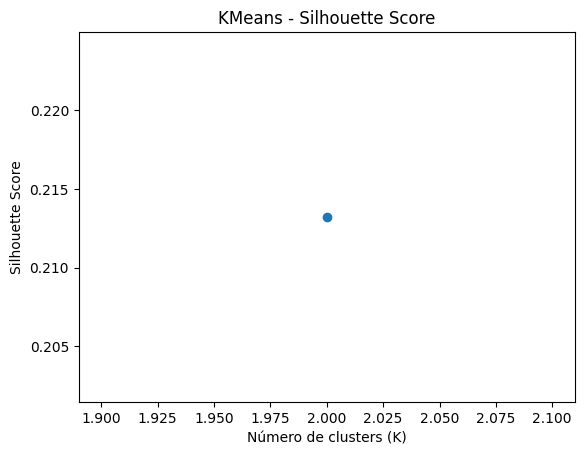

K = 3 | labels únicos: [0 1 2]


/home/matheus2neuron/.pyenv/versions/2neuron_python10/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


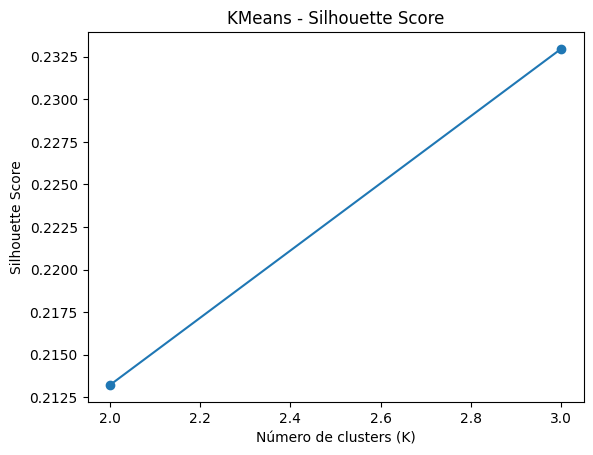

/home/matheus2neuron/.pyenv/versions/2neuron_python10/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


K = 4 | labels únicos: [0 1 2 3]


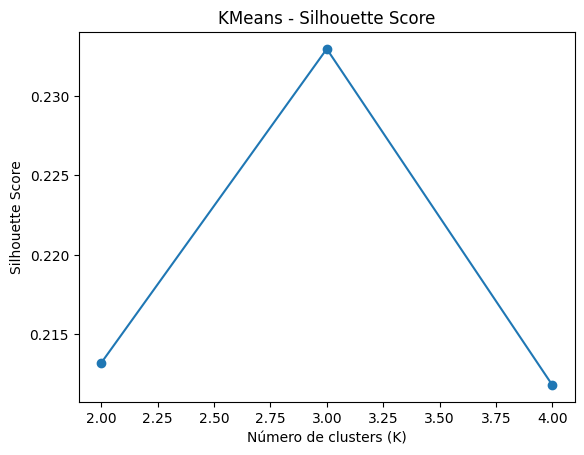

/home/matheus2neuron/.pyenv/versions/2neuron_python10/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


K = 5 | labels únicos: [0 1 2 3 4]


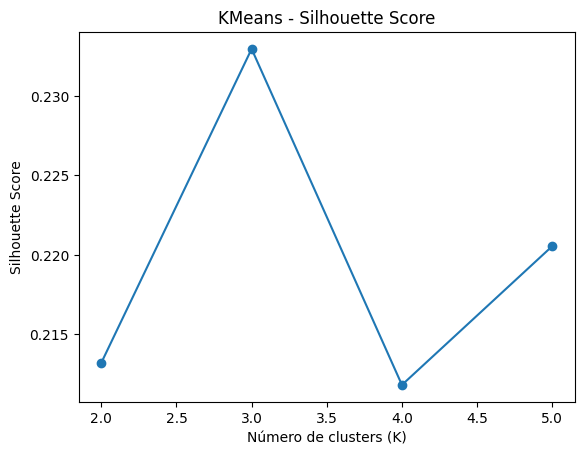

/home/matheus2neuron/.pyenv/versions/2neuron_python10/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


K = 6 | labels únicos: [0 1 2 3 4 5]


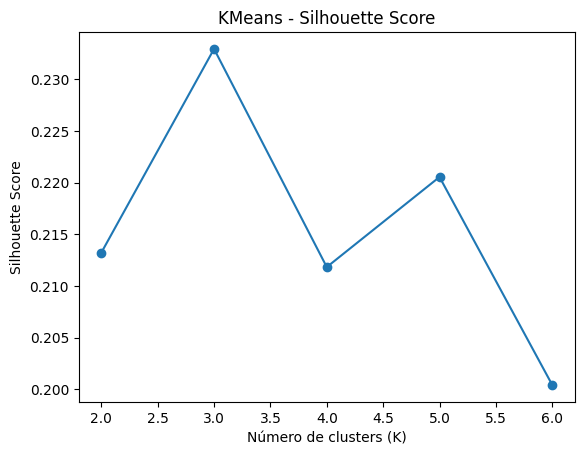

/home/matheus2neuron/.pyenv/versions/2neuron_python10/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


K = 7 | labels únicos: [0 1 2 3 4 5 6]


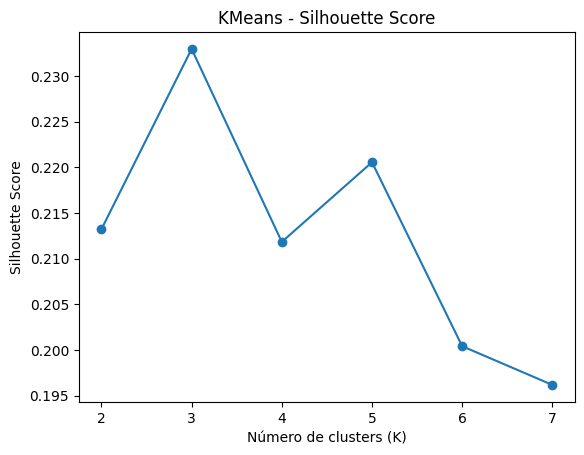

K = 8 | labels únicos: [0 1 2 3 4 5 6 7]


/home/matheus2neuron/.pyenv/versions/2neuron_python10/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


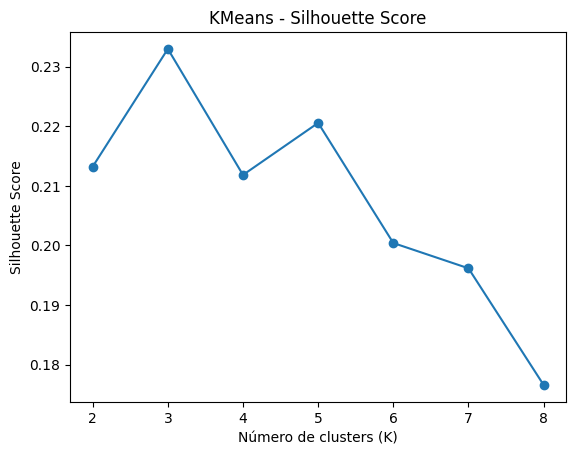

/home/matheus2neuron/.pyenv/versions/2neuron_python10/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


K = 9 | labels únicos: [0 1 2 3 4 5 6 7 8]


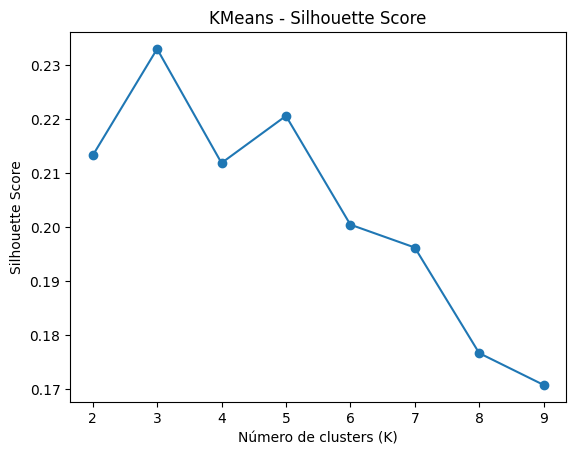

Melhor K =  3
Silhouette Score =  0.23295918228054466


In [18]:
import numpy as np
import matplotlib.pyplot as plt
import time
from sklearn import metrics as mt
from sklearn.cluster import KMeans

k_values = np.arange(2, 10)  # valores de K
ss_list = []

for k in k_values:
    # model definition
    model = KMeans(n_clusters=k, init='random', random_state=42)
    
    # model training + clustering
    labels = model.fit_predict(x_train)
    print("K =", k, "| labels únicos:", np.unique(labels))
    
    # Métrica (só calcula se tiver mais de 1 cluster)
    if len(np.unique(labels)) > 1:
        ss = mt.silhouette_score(x_train, labels)
        ss_list.append(ss)
    else:
        print(f"⚠️ K={k}: só um cluster encontrado, ignorado")
        ss_list.append(-1)  # marcador para ignorar depois

    # Plot (dinâmico)
    plt.plot(k_values[:len(ss_list)], ss_list, marker='o')
    plt.title('KMeans - Silhouette Score')
    plt.xlabel('Número de clusters (K)')
    plt.ylabel('Silhouette Score')
    plt.pause(0.05)  # em vez de sleep

plt.show()

# Melhor K
max_index = np.argmax(ss_list)
print('Melhor K = ', k_values[max_index])
print('Silhouette Score = ', ss_list[max_index])


### 2 - Affinity Propagation
Parâmetros: preference

(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 13)
(178,) (178, 1

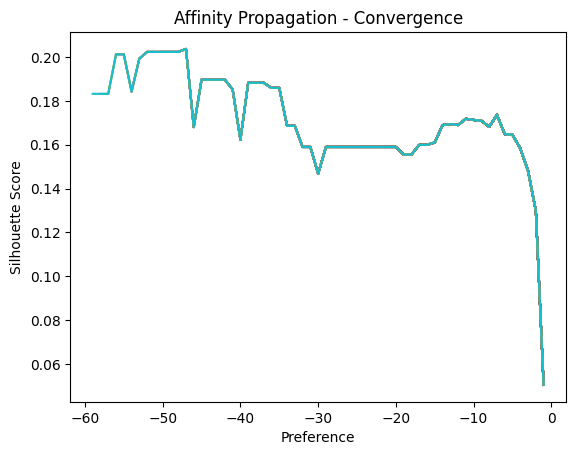

max index =  -47
silhouette score =  0.20365750456597354


<Figure size 640x480 with 0 Axes>

In [14]:
# testing parameter
p = np.arange( -1, -61, -1 )
ss_list = []

for i in range( len( p ) ):
    # model definition
    model = c.AffinityPropagation( preference=p[i] )
    # model training
    model.fit( x_train )
    # clustering
    labels = model.predict( x_train)
    print(labels.shape, x_train.shape)

    # Metric
    ss = mt.silhouette_score( x_train, labels )
    ss_list.append( ss )
    # Plot
    plt.plot( p[:i], ss_list[:i] )
# Plot
plt.title( 'Affinity Propagation - Convergence' )
plt.xlabel( 'Preference' )
plt.ylabel( 'Silhouette Score' )
#display.clear_output(wait=True)
plt.show()
plt.gcf()
time.sleep(0.05)

# Showing final Clustering
max_index = ss_list.index( max( ss_list ) )


print('max index = ', p[max_index])
print('silhouette score = ', ss_list[max_index])